In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
data = pd.read_csv("Sales_and_Marketing.csv")

In [82]:
data.head()

,customer_id,gender,age,country,city,signup_date,last_purchase_date,acquisition_channel,device_type,subscription_type,...,support_tickets,refund_requested,delivery_delay_days,payment_method,satisfaction_score,nps_score,marketing_spend_per_user,lifetime_value,last_3_month_purchase_freq,churn
0,10001,Male,52.0,India,Berlin,10-05-2022 00:00,31-12-2024 00:00,Email,Tablet,Annual,...,0,0,3,UPI,3.0,10,27.56,915.310827,14,0
1,10002,NaN,35.0,Germany,Mumbai,16-06-2024 00:00,07-05-2024 00:00,Organic,Desktop,Monthly,...,5,0,3,BKash,3.0,7,15.15,2079.960938,11,0
2,10003,Female,27.0,Germany,London,23-08-2023 00:00,28-04-2024 00:00,Email,Mobile,Annual,...,1,0,2,UPI,5.0,6,13.51,1379.150885,9,0
3,10004,Female,36.0,India,Mumbai,28-01-2024 00:00,20-05-2023 00:00,Facebook Ads,Tablet,Annual,...,0,0,2,PayPal,4.0,6,25.65,774.652684,7,0
4,10005,Male,29.0,USA,Hamburg,21-07-2023 00:00,07-04-2024 00:00,Referral,Mobile,Monthly,...,2,1,4,BKash,3.0,1,12.39,87.680409,11,0


In [83]:
data.shape

(15000, 30)

In [84]:
data.columns

Index(['customer_id', 'gender', 'age', 'country', 'city', 'signup_date',
       'last_purchase_date', 'acquisition_channel', 'device_type',
       'subscription_type', 'is_premium_user', 'total_visits',
       'avg_session_time', 'pages_per_session', 'email_open_rate',
       'email_click_rate', 'total_spent', 'avg_order_value', 'discount_used',
       'coupon_code', 'support_tickets', 'refund_requested',
       'delivery_delay_days', 'payment_method', 'satisfaction_score',
       'nps_score', 'marketing_spend_per_user', 'lifetime_value',
       'last_3_month_purchase_freq', 'churn'],
      dtype='str')

In [85]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 15000 non-null  int64  
 1   gender                      14262 non-null  str    
 2   age                         13800 non-null  float64
 3   country                     15000 non-null  str    
 4   city                        15000 non-null  str    
 5   signup_date                 15000 non-null  str    
 6   last_purchase_date          15000 non-null  str    
 7   acquisition_channel         15000 non-null  str    
 8   device_type                 15000 non-null  str    
 9   subscription_type           15000 non-null  str    
 10  is_premium_user             15000 non-null  int64  
 11  total_visits                15000 non-null  int64  
 12  avg_session_time            15000 non-null  float64
 13  pages_per_session           15000 non-null

In [86]:
print(data.isnull().sum())

customer_id                      0
gender                         738
age                           1200
country                          0
city                             0
signup_date                      0
last_purchase_date               0
acquisition_channel              0
device_type                      0
subscription_type                0
is_premium_user                  0
total_visits                     0
avg_session_time                 0
pages_per_session                0
email_open_rate                  0
email_click_rate                 0
total_spent                   1050
avg_order_value                  0
discount_used                    0
coupon_code                   6133
support_tickets                  0
refund_requested                 0
delivery_delay_days              0
payment_method                   0
satisfaction_score             702
nps_score                        0
marketing_spend_per_user         0
lifetime_value                   0
last_3_month_purchas

In [87]:
# Calculate Missing-Value
missing = data.isnull().sum()
print(missing[missing > 0])

gender                 738
age                   1200
total_spent           1050
coupon_code           6133
satisfaction_score     702
dtype: int64


In [88]:
# Calculate Missing-Value Percentage

missing_percentage = (data.isnull().sum() / len(data)) * 100
print(missing_percentage[missing_percentage > 0])

gender                 4.920000
age                    8.000000
total_spent            7.000000
coupon_code           40.886667
satisfaction_score     4.680000
dtype: float64


In [89]:
# Check Duplicate Rows
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [90]:
data.describe()

,customer_id,age,is_premium_user,total_visits,avg_session_time,pages_per_session,email_open_rate,email_click_rate,total_spent,avg_order_value,discount_used,support_tickets,refund_requested,delivery_delay_days,satisfaction_score,nps_score,marketing_spend_per_user,lifetime_value,last_3_month_purchase_freq,churn
count,15000.000000,13800.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,13950.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,14298.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,17500.500000,35.203913,0.304467,15.000933,8.020805,4.002901,0.496278,0.251231,524.357397,60.080882,0.494467,1.995600,0.147667,2.981333,3.588754,4.968667,17.575238,1235.698200,6.975133,0.153200
std,4330.271354,10.334384,0.460197,3.892704,2.991499,1.479846,0.290108,0.144689,467.050070,24.746203,0.499986,1.421214,0.354781,1.720537,1.088703,3.155495,7.183437,657.521849,4.323443,0.360192
min,10001.000000,-4.000000,0.000000,3.000000,0.006095,0.007845,0.000000,0.000000,0.267291,0.071596,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,5.000000,0.368886,0.000000,0.000000
25%,13750.750000,28.000000,0.000000,12.000000,5.974555,2.989150,0.240000,0.130000,300.432074,43.032470,0.000000,1.000000,0.000000,2.000000,3.000000,2.000000,11.380000,741.301251,3.000000,0.000000
50%,17500.500000,35.000000,0.000000,15.000000,7.991907,3.996992,0.500000,0.250000,498.843859,60.108827,0.000000,2.000000,0.000000,3.000000,4.000000,5.000000,17.630000,1216.210685,7.000000,0.000000
75%,21250.250000,42.000000,1.000000,18.000000,10.059986,5.014406,0.750000,0.380000,702.396635,76.888445,1.000000,3.000000,0.000000,4.000000,4.000000,8.000000,23.770000,1677.860399,11.000000,0.000000
max,25000.000000,95.000000,1.000000,31.000000,19.123716,10.843172,1.000000,0.500000,15910.431880,154.554696,1.000000,9.000000,1.000000,11.000000,5.000000,10.000000,30.000000,3767.490455,14.000000,1.000000


In [91]:
# Identify Numerical Columns
numerical_columns = data.select_dtypes(include=np.number).columns
print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['customer_id', 'age', 'is_premium_user', 'total_visits', 'avg_session_time', 'pages_per_session', 'email_open_rate', 'email_click_rate', 'total_spent', 'avg_order_value', 'discount_used', 'support_tickets', 'refund_requested', 'delivery_delay_days', 'satisfaction_score', 'nps_score', 'marketing_spend_per_user', 'lifetime_value', 'last_3_month_purchase_freq', 'churn']


In [92]:
# Identify Categorical Columns
categorical_columns = data.select_dtypes(exclude=np.number).columns
print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['gender', 'country', 'city', 'signup_date', 'last_purchase_date', 'acquisition_channel', 'device_type', 'subscription_type', 'coupon_code', 'payment_method']


In [93]:
# Check the Categories
for col in categorical_columns:
    print("\n---", col, "---")
    print(data[col].value_counts(dropna=False).head(10))


--- gender ---
gender
Male      6844
Female    6686
NaN        738
Other      732
Name: count, dtype: int64

--- country ---
country
Germany       3072
India         3014
Bangladesh    2984
USA           2975
UK            2955
Name: count, dtype: int64

--- city ---
city
London      2236
Mumbai      2184
Dhaka       2178
New York    2135
Delhi       2128
Berlin      2075
Hamburg     2064
Name: count, dtype: int64

--- signup_date ---
signup_date
20-09-2024 00:00    29
03-06-2022 00:00    28
11-05-2024 00:00    27
10-02-2024 00:00    27
03-11-2023 00:00    26
05-02-2024 00:00    26
29-07-2023 00:00    25
18-06-2024 00:00    25
26-09-2023 00:00    25
12-02-2022 00:00    25
Name: count, dtype: int64

--- last_purchase_date ---
last_purchase_date
17-01-2025 00:00    32
13-08-2023 00:00    31
23-06-2023 00:00    31
01-11-2024 00:00    30
09-07-2023 00:00    30
28-08-2023 00:00    30
09-03-2024 00:00    29
02-03-2023 00:00    29
31-03-2024 00:00    29
10-02-2023 00:00    29
Name: count, dt

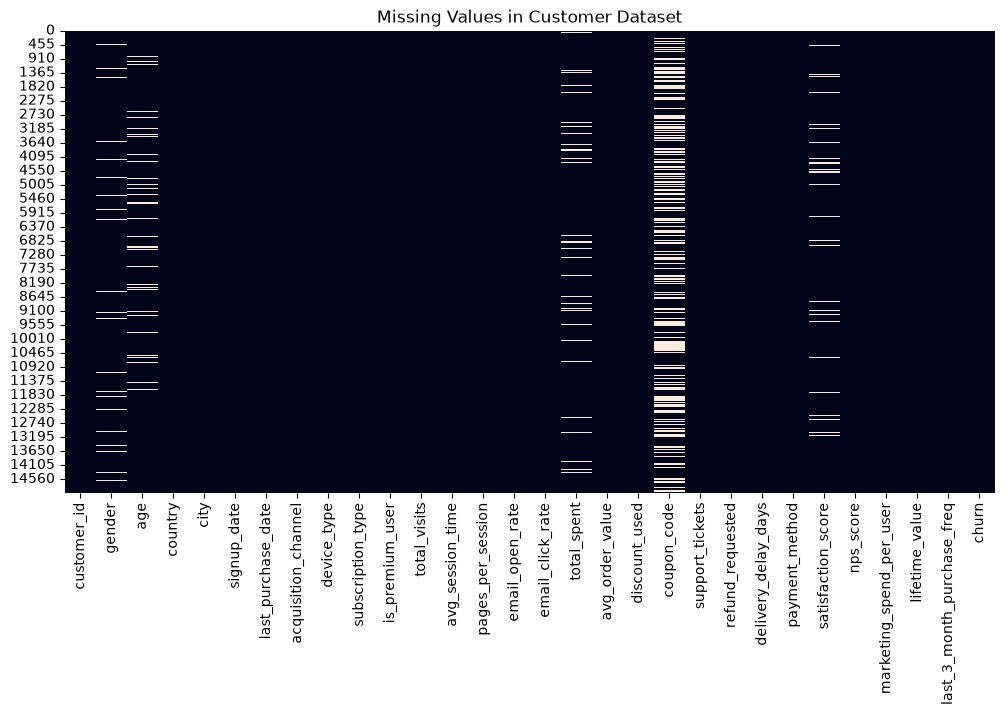

In [94]:
# Visualize Missing Values
plt.figure(figsize=(12, 6))
sns.heatmap(data.isnull(), cbar=False)
plt.title("Missing Values in Customer Dataset")
plt.show()

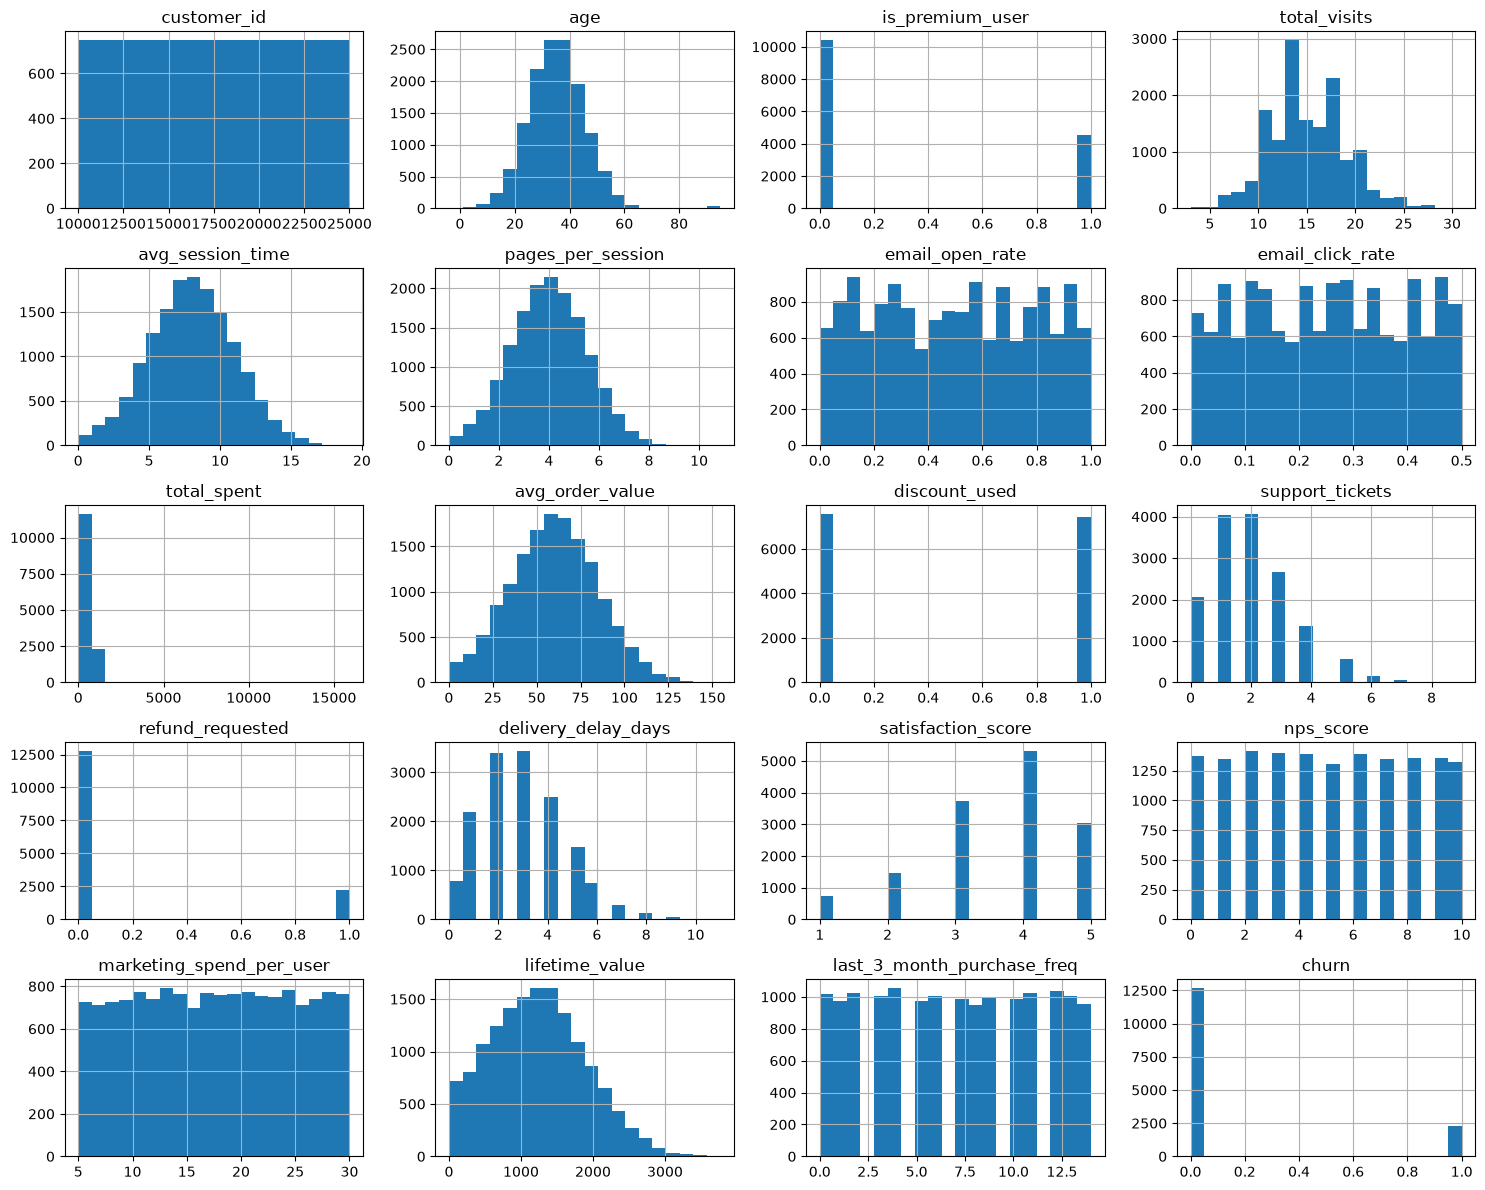

In [95]:
# visualize numerical data
data[numerical_columns].hist(figsize=(15, 12), bins=20)

plt.tight_layout()
plt.show()

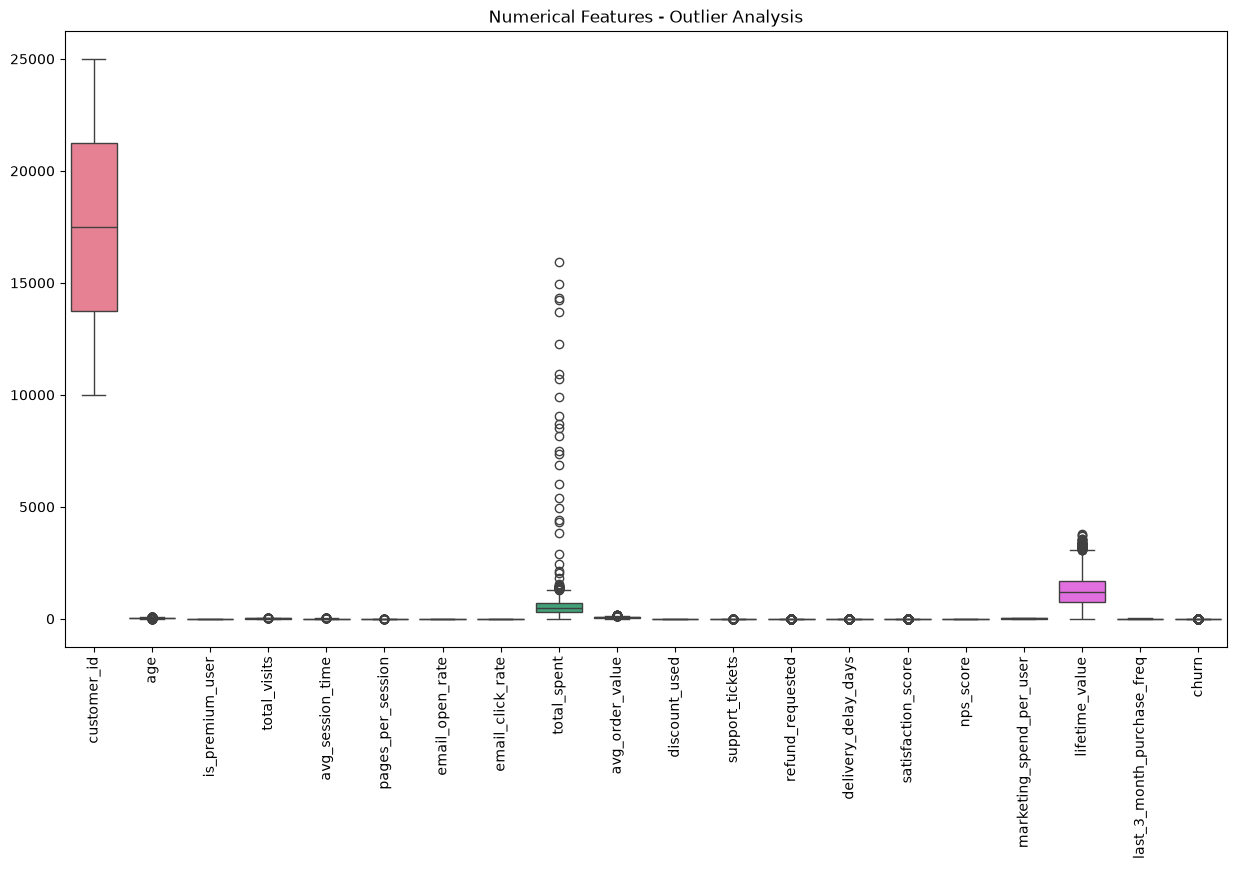

In [96]:
# check outliers
plt.figure(figsize=(15, 8))
sns.boxplot(data=data[numerical_columns])
plt.xticks(rotation=90)
plt.title("Numerical Features - Outlier Analysis")
plt.show()

In [97]:
data['gender'] = data['gender'].fillna(data['gender'].mode()[0])

In [98]:
print(data['gender'].isnull().sum())

0


In [99]:
data['age'] = data['age'].fillna(data['age'].median())

In [100]:
print(data['age'].isnull().sum())

0


In [101]:
data['total_spent'] = data['total_spent'].fillna(data['total_spent'].median())

In [102]:
print(data['total_spent'].isnull().sum())

0


In [103]:
data['coupon_code'] = data['coupon_code'].fillna('No_Coupon')

In [104]:
print(data['coupon_code'].isnull().sum())

0


In [105]:
data['satisfaction_score'] = data['satisfaction_score'].fillna(
    data['satisfaction_score'].median()
)

In [106]:
print(data['satisfaction_score'].isnull().sum())

0


In [107]:
print(data.isnull().sum()[data.isnull().sum() > 0])

Series([], dtype: int64)


In [108]:
data['signup_date'] = pd.to_datetime(
    data['signup_date'],
    format='%d-%m-%Y %H:%M'
)

data['last_purchase_date'] = pd.to_datetime(
    data['last_purchase_date'],
    format='%d-%m-%Y %H:%M'
)

print(data[['signup_date', 'last_purchase_date']].head())

  signup_date last_purchase_date
0  2022-05-10         2024-12-31
1  2024-06-16         2024-05-07
2  2023-08-23         2024-04-28
3  2024-01-28         2023-05-20
4  2023-07-21         2024-04-07


In [109]:
print(data[['signup_date', 'last_purchase_date']].dtypes)

signup_date           datetime64[us]
last_purchase_date    datetime64[us]
dtype: object


In [110]:
# Create customer_tenure_days (first version; recomputed correctly below)
data['customer_tenure_days'] = (
    data['last_purchase_date'] - data['signup_date']
).dt.days

In [111]:
print(data[['signup_date',
            'last_purchase_date',
            'customer_tenure_days']].head())

  signup_date last_purchase_date  customer_tenure_days
0  2022-05-10         2024-12-31                   966
1  2024-06-16         2024-05-07                   -40
2  2023-08-23         2024-04-28                   249
3  2024-01-28         2023-05-20                  -253
4  2023-07-21         2024-04-07                   261


In [112]:
reference_date = data['last_purchase_date'].max()

print(reference_date)

2025-03-10 00:00:00


In [113]:
data['days_since_last_purchase'] = (
    reference_date - data['last_purchase_date']
).dt.days

In [114]:
print(data[['customer_tenure_days',
            'days_since_last_purchase']].head())

   customer_tenure_days  days_since_last_purchase
0                   966                        69
1                   -40                       307
2                   249                       316
3                  -253                       660
4                   261                       337


In [115]:
invalid_dates = data['last_purchase_date'] < data['signup_date']

print("Invalid date records:", invalid_dates.sum())

Invalid date records: 3762


In [116]:
print(data['customer_tenure_days'].min())

-627


In [117]:
print(data['customer_tenure_days'].describe())

count    15000.000000
mean       264.791133
std        369.240516
min       -627.000000
25%         -2.000000
50%        266.000000
75%        526.250000
max       1157.000000
Name: customer_tenure_days, dtype: float64


In [118]:
print(data.loc[invalid_dates, 
               ['signup_date', 'last_purchase_date']].head(10))

   signup_date last_purchase_date
1   2024-06-16         2024-05-07
3   2024-01-28         2023-05-20
5   2024-05-08         2023-01-20
12  2023-03-14         2023-01-25
13  2024-09-14         2023-01-31
21  2023-10-20         2023-01-11
22  2024-04-23         2024-02-15
23  2024-01-31         2023-06-14
29  2024-05-13         2023-08-01
32  2024-03-30         2023-02-05


In [119]:
reference_date = data['last_purchase_date'].max()

data['customer_tenure_days'] = (
    reference_date - data['signup_date']
).dt.days

In [120]:
print(data['customer_tenure_days'].describe())

count    15000.00000
mean       664.09300
std        290.06906
min        165.00000
25%        413.00000
50%        661.00000
75%        918.00000
max       1164.00000
Name: customer_tenure_days, dtype: float64


In [121]:
print(data['customer_tenure_days'].min())

165


In [122]:
print(data['days_since_last_purchase'].describe())

count    15000.000000
mean       399.301867
std        231.520502
min          0.000000
25%        197.000000
50%        397.000000
75%        602.000000
max        799.000000
Name: days_since_last_purchase, dtype: float64


In [123]:
print(data[['last_purchase_date',
            'days_since_last_purchase']].head())

  last_purchase_date  days_since_last_purchase
0         2024-12-31                        69
1         2024-05-07                       307
2         2024-04-28                       316
3         2023-05-20                       660
4         2024-04-07                       337


In [124]:
data['invalid_purchase_date'] = (
    data['last_purchase_date'] < data['signup_date']
).astype(int)

In [125]:
print(data['invalid_purchase_date'].value_counts())

invalid_purchase_date
0    11238
1     3762
Name: count, dtype: int64


In [126]:
data = data.drop(columns=['signup_date', 'last_purchase_date'])

In [127]:
print(data.columns)

Index(['customer_id', 'gender', 'age', 'country', 'city',
       'acquisition_channel', 'device_type', 'subscription_type',
       'is_premium_user', 'total_visits', 'avg_session_time',
       'pages_per_session', 'email_open_rate', 'email_click_rate',
       'total_spent', 'avg_order_value', 'discount_used', 'coupon_code',
       'support_tickets', 'refund_requested', 'delivery_delay_days',
       'payment_method', 'satisfaction_score', 'nps_score',
       'marketing_spend_per_user', 'lifetime_value',
       'last_3_month_purchase_freq', 'churn', 'customer_tenure_days',
       'days_since_last_purchase', 'invalid_purchase_date'],
      dtype='str')


In [128]:
print(data.shape)

(15000, 31)


In [129]:
# to see how many unique values each categorical column has
categorical_columns = [
    'gender',
    'country',
    'city',
    'acquisition_channel',
    'device_type',
    'subscription_type',
    'coupon_code',
    'payment_method'
]

print(data[categorical_columns].nunique())

gender                 3
country                5
city                   7
acquisition_channel    5
device_type            3
subscription_type      2
coupon_code            4
payment_method         5
dtype: int64


In [130]:
data = pd.get_dummies(
    data,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

In [131]:
print(data.shape)

(15000, 49)


In [132]:
print(data.dtypes)

customer_id                           int64
age                                 float64
is_premium_user                       int64
total_visits                          int64
avg_session_time                    float64
pages_per_session                   float64
email_open_rate                     float64
email_click_rate                    float64
total_spent                         float64
avg_order_value                     float64
discount_used                         int64
support_tickets                       int64
refund_requested                      int64
delivery_delay_days                   int64
satisfaction_score                  float64
nps_score                             int64
marketing_spend_per_user            float64
lifetime_value                      float64
last_3_month_purchase_freq            int64
churn                                 int64
customer_tenure_days                  int64
days_since_last_purchase              int64
invalid_purchase_date           

In [133]:
print(data.head())

   customer_id   age  is_premium_user  total_visits  avg_session_time  \
0        10001  52.0                1             7         13.903745   
1        10002  35.0                0            19          5.112528   
2        10003  27.0                1            18          9.742749   
3        10004  36.0                1            16          9.642654   
4        10005  29.0                0            12          7.791291   

   pages_per_session  email_open_rate  email_click_rate  total_spent  \
0           5.415164             0.67              0.26   559.524958   
1           5.352441             0.70              0.37   356.491344   
2           3.594719             0.47              0.44   689.332196   
3           2.949531             0.58              0.37   445.429636   
4           2.405539             0.05              0.16   686.286022   

   avg_order_value  ...  device_type_Mobile  device_type_Tablet  \
0        65.246704  ...                   0                  

In [134]:
print([col for col in data.columns if 'gender' in col])

['gender_Male', 'gender_Other']


In [135]:
print("Shape:", data.shape)

Shape: (15000, 49)


In [136]:
print(data.isnull().sum()[data.isnull().sum() > 0])

Series([], dtype: int64)


## Clustering (corrected)
Changes made vs. the original notebook:
- KMeans / elbow / silhouette / PCA now use `cluster_scaled` (previously the scaled data was created but never used).
- One-hot dummies removed from clustering features (they distort KMeans; `city` duplicates `country`).
- `satisfaction_score` no longer capped as an outlier (bounded score, outliers came from median imputation).
- `optimal_k` now chosen from silhouette scores (override manually if needed); segment names are assigned from mean `lifetime_value` instead of hardcoded.
- Duplicate cells removed. Note: ~25% of rows have `last_purchase_date` < `signup_date` (data-quality issue, flagged in `invalid_purchase_date`).

In [137]:
# Use only behavioural / spending features for clustering.
# One-hot dummies (gender, country, city, payment, etc.) are dropped:
# KMeans handles 0/1 dummies poorly, and city fully determines country.
dummy_prefixes = ('gender_', 'country_', 'city_', 'acquisition_channel_',
                  'device_type_', 'subscription_type_', 'coupon_code_',
                  'payment_method_')

drop_cols = ['customer_id', 'churn', 'invalid_purchase_date'] + \
            [c for c in data.columns if c.startswith(dummy_prefixes)]

cluster_data = data.drop(columns=drop_cols)

In [138]:
print(cluster_data.shape)

(15000, 20)


In [139]:
print(cluster_data.columns.tolist())

['age', 'is_premium_user', 'total_visits', 'avg_session_time', 'pages_per_session', 'email_open_rate', 'email_click_rate', 'total_spent', 'avg_order_value', 'discount_used', 'support_tickets', 'refund_requested', 'delivery_delay_days', 'satisfaction_score', 'nps_score', 'marketing_spend_per_user', 'lifetime_value', 'last_3_month_purchase_freq', 'customer_tenure_days', 'days_since_last_purchase']


In [140]:
print(cluster_data.dtypes.value_counts())

float64    10
int64      10
Name: count, dtype: int64


In [141]:
print(cluster_data.head())

    age  is_premium_user  total_visits  avg_session_time  pages_per_session  \
0  52.0                1             7         13.903745           5.415164   
1  35.0                0            19          5.112528           5.352441   
2  27.0                1            18          9.742749           3.594719   
3  36.0                1            16          9.642654           2.949531   
4  29.0                0            12          7.791291           2.405539   

   email_open_rate  email_click_rate  total_spent  avg_order_value  \
0             0.67              0.26   559.524958        65.246704   
1             0.70              0.37   356.491344        48.473887   
2             0.47              0.44   689.332196        77.815371   
3             0.58              0.37   445.429636        71.712192   
4             0.05              0.16   686.286022        44.990246   

   discount_used  support_tickets  refund_requested  delivery_delay_days  \
0              0            

In [142]:
numerical_features = [
    'age',
    'total_visits',
    'avg_session_time',
    'pages_per_session',
    'email_open_rate',
    'email_click_rate',
    'total_spent',
    'avg_order_value',
    'support_tickets',
    'delivery_delay_days',
    'satisfaction_score',
    'nps_score',
    'marketing_spend_per_user',
    'lifetime_value',
    'last_3_month_purchase_freq',
    'customer_tenure_days',
    'days_since_last_purchase'
]

In [143]:
outlier_counts = {}

for col in numerical_features:
    Q1 = cluster_data[col].quantile(0.25)
    Q3 = cluster_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        (cluster_data[col] < lower) |
        (cluster_data[col] > upper)
    ).sum()

print(pd.Series(outlier_counts).sort_values(ascending=False))

satisfaction_score            753
age                           218
delivery_delay_days           184
total_spent                   119
support_tickets                79
lifetime_value                 56
avg_order_value                54
avg_session_time               45
total_visits                   39
pages_per_session              33
email_open_rate                 0
email_click_rate                0
nps_score                       0
marketing_spend_per_user        0
last_3_month_purchase_freq      0
customer_tenure_days            0
days_since_last_purchase        0
dtype: int64


In [144]:
# Cap outliers (satisfaction_score excluded: it is a bounded score and its
# "outliers" were created by median imputation, not real extreme values)
outlier_features = [
    'age',
    'delivery_delay_days',
    'total_spent',
    'support_tickets',
    'lifetime_value',
    'avg_order_value',
    'avg_session_time',
    'total_visits',
    'pages_per_session'
]

for col in outlier_features:
    Q1 = cluster_data[col].quantile(0.25)
    Q3 = cluster_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    cluster_data[col] = cluster_data[col].clip(lower=lower, upper=upper)

print("Outliers capped successfully.")

Outliers capped successfully.


In [145]:
outlier_counts_after = {}

for col in numerical_features:
    Q1 = cluster_data[col].quantile(0.25)
    Q3 = cluster_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_counts_after[col] = (
        (cluster_data[col] < lower) |
        (cluster_data[col] > upper)
    ).sum()

print(pd.Series(outlier_counts_after).sort_values(ascending=False))

satisfaction_score            753
age                             0
total_visits                    0
pages_per_session               0
avg_session_time                0
email_click_rate                0
total_spent                     0
avg_order_value                 0
email_open_rate                 0
support_tickets                 0
delivery_delay_days             0
nps_score                       0
marketing_spend_per_user        0
lifetime_value                  0
last_3_month_purchase_freq      0
customer_tenure_days            0
days_since_last_purchase        0
dtype: int64


In [146]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

cluster_scaled = scaler.fit_transform(cluster_data)
cluster_scaled = pd.DataFrame(
    cluster_scaled,
    columns=cluster_data.columns,
    index=cluster_data.index
)
print(cluster_scaled.shape)
print(cluster_scaled.head())


(15000, 20)
        age  is_premium_user  total_visits  avg_session_time  \
0  1.783686         1.511434     -2.062081          1.971522   
1 -0.012418        -0.661623      1.032356         -0.973562   
2 -0.857643         1.511434      0.774486          0.577576   
3  0.093235         1.511434      0.258746          0.544043   
4 -0.646337        -0.661623     -0.772732         -0.076169   

   pages_per_session  email_open_rate  email_click_rate  total_spent  \
0           0.957387         0.598838          0.060605     0.184472   
1           0.914900         0.702251          0.820879    -0.572255   
2          -0.275728        -0.090583          1.304690     0.668276   
3          -0.712759         0.288598          0.820879    -0.240773   
4          -1.081243        -1.538367         -0.630553     0.656923   

   avg_order_value  discount_used  support_tickets  refund_requested  \
0         0.210730      -0.988994        -1.421531         -0.416233   
1        -0.469567       1

In [147]:
from sklearn.cluster import KMeans

print("KMeans imported successfully")

KMeans imported successfully


In [148]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(cluster_scaled)          # <-- scaled data
    inertia.append(kmeans.inertia_)

print(inertia)

[284976.68363505974, 272182.56274057215, 263276.60479218187, 259159.8094888751, 255993.1646927056, 253447.13160914878, 250326.1823515686, 247991.22131476435, 244971.67621215642]


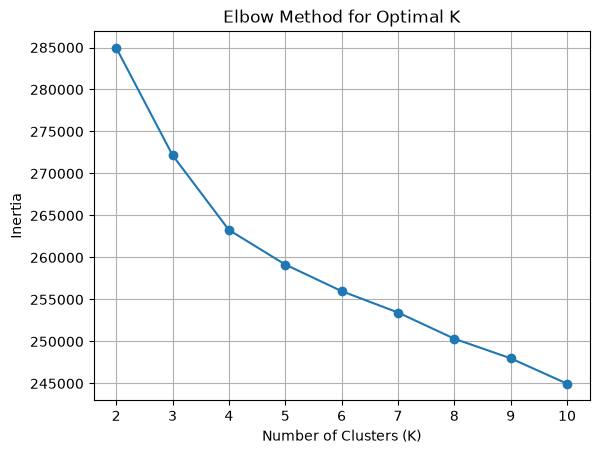

In [149]:
import matplotlib.pyplot as plt

k_values = range(2, 11)

plt.plot(k_values, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [150]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(cluster_scaled)   # <-- scaled data

    score = silhouette_score(
        cluster_scaled, labels,
        sample_size=5000, random_state=42
    )
    silhouette_scores.append(score)

for k, s in zip(range(2, 11), silhouette_scores):
    print(f"k={k}: silhouette={s:.4f}")

k=2: silhouette=0.0514
k=3: silhouette=0.0569
k=4: silhouette=0.0519
k=5: silhouette=0.0471
k=6: silhouette=0.0407
k=7: silhouette=0.0341
k=8: silhouette=0.0323
k=9: silhouette=0.0333
k=10: silhouette=0.0335


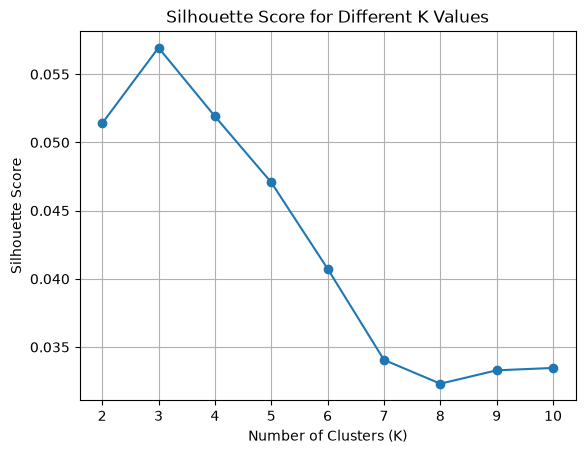

In [151]:
import matplotlib.pyplot as plt

k_values = range(2, 11)

plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [152]:
# Final K-Means model
# K is picked as the best silhouette score. Look at the elbow + silhouette
# plots above and OVERRIDE this (e.g. optimal_k = 4) if the business
# interpretation is better with a different K.
k_values = list(range(2, 11))
optimal_k = k_values[int(np.argmax(silhouette_scores))]

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(cluster_scaled)   # <-- scaled data

print("K-Means model trained successfully!")
print("Number of clusters:", optimal_k)
print("Cluster labels:", cluster_labels[:10])

K-Means model trained successfully!
Number of clusters: 3
Cluster labels: [0 2 0 0 1 0 2 2 0 0]


In [153]:
data['Cluster'] = cluster_labels

print(data[['Cluster']].head())

   Cluster
0        0
1        2
2        0
3        0
4        1


In [154]:
print(data['Cluster'].value_counts().sort_index())

Cluster
0    6475
1    2215
2    6310
Name: count, dtype: int64


In [155]:
# Create customer cluster profiles

cluster_profile = data.groupby('Cluster').mean(numeric_only=True)

print(cluster_profile)

          customer_id        age  is_premium_user  total_visits  \
Cluster                                                           
0        17490.287259  35.200000         0.299923     14.980077   
1        17363.340858  35.119639         0.305192     15.007223   
2        17559.126783  35.198732         0.308875     15.020127   

         avg_session_time  pages_per_session  email_open_rate  \
Cluster                                                         
0                8.018301           3.989313         0.496261   
1                7.989942           3.982990         0.504605   
2                8.034210           4.023833         0.493372   

         email_click_rate  total_spent  avg_order_value  ...  \
Cluster                                                  ...   
0                0.253742   533.703526        60.581732  ...   
1                0.252488   517.178618        60.223244  ...   
2                0.248214   513.041328        59.516962  ...   

         device_t

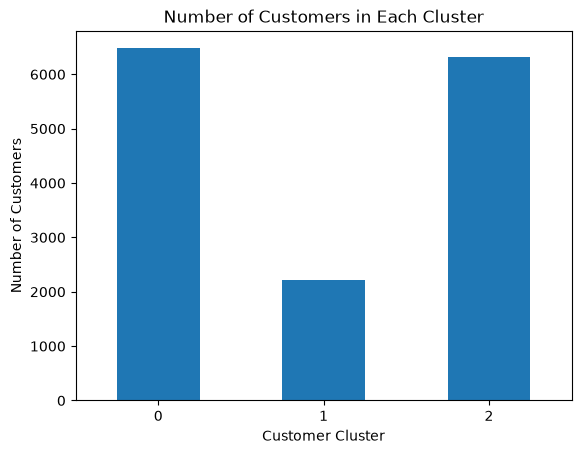

In [157]:
import matplotlib.pyplot as plt

cluster_counts = data['Cluster'].value_counts().sort_index()

cluster_counts.plot(kind='bar')

plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.title('Number of Customers in Each Cluster')
plt.xticks(rotation=0)
plt.show()

In [158]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce the scaled features to 2 components for plotting
pca = PCA(n_components=2)

cluster_pca = pca.fit_transform(cluster_scaled)   # <-- scaled data

print("PCA shape:", cluster_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.round(3))

PCA shape: (15000, 2)
Explained variance: [0.053 0.052]


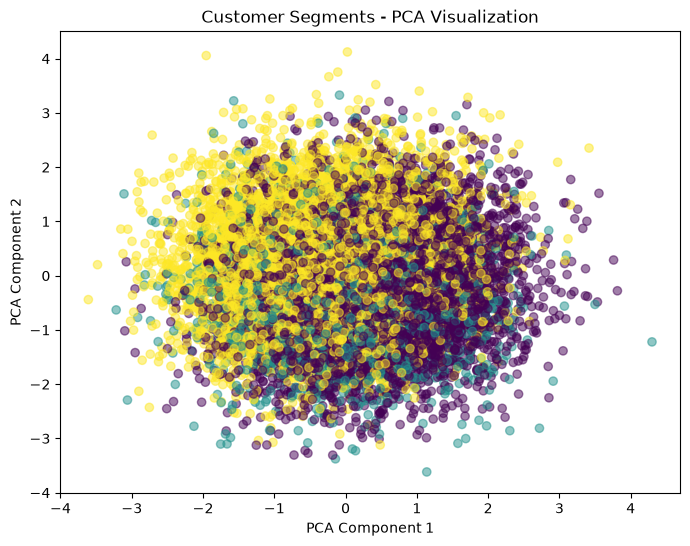

In [159]:
plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_pca[:, 0],
    cluster_pca[:, 1],
    c=cluster_labels,
    alpha=0.5
)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('Customer Segments - PCA Visualization')
plt.show()

In [160]:
# Customer Cluster Profile

cluster_profile = data.groupby('Cluster').mean(numeric_only=True)

display(cluster_profile.T)

Cluster,0,1,2
customer_id,17490.287259,17363.340858,17559.126783
age,35.200000,35.119639,35.198732
is_premium_user,0.299923,0.305192,0.308875
total_visits,14.980077,15.007223,15.020127
avg_session_time,8.018301,7.989942,8.034210
pages_per_session,3.989313,3.982990,4.023833
email_open_rate,0.496261,0.504605,0.493372
email_click_rate,0.253742,0.252488,0.248214
total_spent,533.703526,517.178618,513.041328
avg_order_value,60.581732,60.223244,59.516962


In [161]:
# Name clusters from the data (ranked by mean lifetime_value),
# instead of guessing which label is "high value".
ltv_rank = (
    data.groupby('Cluster')['lifetime_value']
        .mean()
        .sort_values()
        .index.tolist()          # lowest -> highest
)

k = len(ltv_rank)
if k == 2:
    tier_names = ['Low-Value Customers', 'High-Value Customers']
elif k == 3:
    tier_names = ['Low-Value Customers', 'Mid-Value Customers', 'High-Value Customers']
else:
    tier_names = [f'Tier {i+1} of {k} (by lifetime value)' for i in range(k)]

segment_names = {cluster: name for cluster, name in zip(ltv_rank, tier_names)}
print(segment_names)

data['Customer_Segment'] = data['Cluster'].map(segment_names)

print(data[['Cluster', 'Customer_Segment']].head(10))

{1: 'Low-Value Customers', 0: 'Mid-Value Customers', 2: 'High-Value Customers'}
   Cluster      Customer_Segment
0        0   Mid-Value Customers
1        2  High-Value Customers
2        0   Mid-Value Customers
3        0   Mid-Value Customers
4        1   Low-Value Customers
5        0   Mid-Value Customers
6        2  High-Value Customers
7        2  High-Value Customers
8        0   Mid-Value Customers
9        0   Mid-Value Customers


In [162]:
print(data['Customer_Segment'].value_counts())

Customer_Segment
Mid-Value Customers     6475
High-Value Customers    6310
Low-Value Customers     2215
Name: count, dtype: int64


In [163]:
# Final Customer Segment Analysis

segment_analysis = data.groupby('Customer_Segment').agg({
    'total_spent': 'mean',
    'avg_order_value': 'mean',
    'last_3_month_purchase_freq': 'mean',
    'lifetime_value': 'mean',
    'satisfaction_score': 'mean',
    'churn': 'mean',
    'customer_tenure_days': 'mean'
}).round(2)

display(segment_analysis)

,total_spent,avg_order_value,last_3_month_purchase_freq,lifetime_value,satisfaction_score,churn,customer_tenure_days
Customer_Segment,,,,,,,
High-Value Customers,513.04,59.52,6.95,1241.16,3.61,0.15,662.68
Low-Value Customers,517.18,60.22,7.00,1229.41,3.61,0.15,667.23
Mid-Value Customers,533.70,60.58,6.99,1232.53,3.60,0.15,664.40


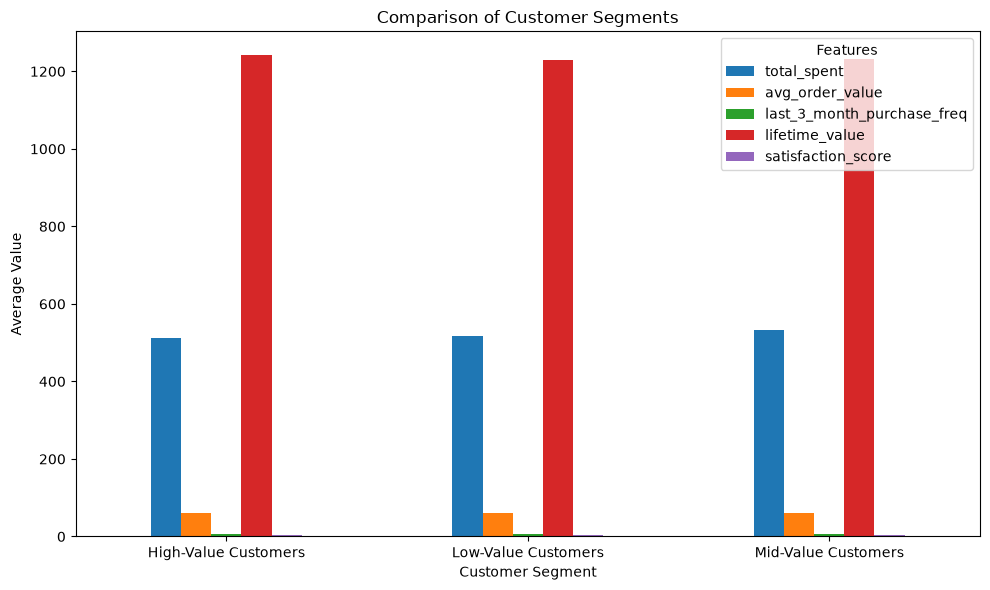

In [164]:
# Compare important customer features

features = [
    'total_spent',
    'avg_order_value',
    'last_3_month_purchase_freq',
    'lifetime_value',
    'satisfaction_score'
]

segment_analysis[features].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.xlabel('Customer Segment')
plt.ylabel('Average Value')
plt.title('Comparison of Customer Segments')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.tight_layout()
plt.show()

In [165]:
# Create final customer segmentation dataset

final_data = data.copy()

print("Final dataset shape:", final_data.shape)
display(final_data.head())

Final dataset shape: (15000, 51)


,customer_id,age,is_premium_user,total_visits,avg_session_time,pages_per_session,email_open_rate,email_click_rate,total_spent,avg_order_value,...,subscription_type_Monthly,coupon_code_No_Coupon,coupon_code_REF10,coupon_code_SALE15,payment_method_Card,payment_method_PayPal,payment_method_SEPA,payment_method_UPI,Cluster,Customer_Segment
0,10001,52.0,1,7,13.903745,5.415164,0.67,0.26,559.524958,65.246704,...,0,0,0,0,0,0,0,1,0,Mid-Value Customers
1,10002,35.0,0,19,5.112528,5.352441,0.70,0.37,356.491344,48.473887,...,1,0,0,0,0,0,0,0,2,High-Value Customers
2,10003,27.0,1,18,9.742749,3.594719,0.47,0.44,689.332196,77.815371,...,0,1,0,0,0,0,0,1,0,Mid-Value Customers
3,10004,36.0,1,16,9.642654,2.949531,0.58,0.37,445.429636,71.712192,...,0,1,0,0,0,1,0,0,0,Mid-Value Customers
4,10005,29.0,0,12,7.791291,2.405539,0.05,0.16,686.286022,44.990246,...,1,1,0,0,0,0,0,0,1,Low-Value Customers


In [166]:
# Save the final dataset

final_data.to_csv('customer_segmentation_final.csv', index=False)

print("Final customer segmentation dataset saved successfully!")

Final customer segmentation dataset saved successfully!


In [167]:
# Final Project Check

print("Total Customers:", len(final_data))
print("Number of Clusters:", final_data['Cluster'].nunique())

print("\nCustomer Segments:")
print(final_data['Customer_Segment'].value_counts())

print("\nFinal Dataset Shape:")
print(final_data.shape)

print("\nColumns Added:")
print(['Cluster', 'Customer_Segment'])

Total Customers: 15000
Number of Clusters: 3

Customer Segments:
Customer_Segment
Mid-Value Customers     6475
High-Value Customers    6310
Low-Value Customers     2215
Name: count, dtype: int64

Final Dataset Shape:
(15000, 51)

Columns Added:
['Cluster', 'Customer_Segment']


In [168]:
from sklearn.metrics import silhouette_score

final_silhouette_score = silhouette_score(
    cluster_scaled,
    cluster_labels,
    sample_size=5000,
    random_state=42
)

print("Final Silhouette Score:", round(final_silhouette_score, 4))
print("Number of Clusters:", kmeans_final.n_clusters)
print("Number of Customers:", len(cluster_labels))

Final Silhouette Score: 0.0569
Number of Clusters: 3
Number of Customers: 15000
